# Unexpected demand shock, cohort by cohort

Builds on `steady_state.ipynb`.  The economy sits in the steady state computed there, and at
$t=0$ an **unexpected** demand shock hits.  Nothing before $t=0$ was conditioned on it; from
$t=0$ on there is perfect foresight.

## Which producers can respond, and when

Producer $i$ hires its labour at date $s$ and delivers $\tau_i$ periods later, at $s+\tau_i$.
So the goods delivered at date $t$ by producer $i$ were committed at date $t-\tau_i$:

$$\text{delivery }y_{i,t}\ \text{was chosen at}\ t-\tau_i
\quad\Longrightarrow\quad
\begin{cases}
t-\tau_i<0: & \text{chosen before the shock} \;\Rightarrow\; \textbf{locked at }y_i^{ss}\\[2pt]
t-\tau_i\ge 0: & \text{chosen after the shock} \;\Rightarrow\; \textbf{free}
\end{cases}$$

so the set of producers that have responded by date $t$ is exactly $\{i:\tau_i\le t\}$:

| date | who can move |
|---|---|
| $t=0$ | only $\Delta=0$ |
| $t=1$ | $\Delta=0,1$ |
| $t=2$ | $\Delta=0,1,2$ |
| $t\ge\max_i\tau_i$ | everyone — the economy is back to flexible prices |

At $t=0$ the final-good producer therefore buys the steady-state quantity from all 268
producers with $\Delta\ge1$, and only the single $\Delta=0$ producer's quantity can change.
This is the same staggering the shock notebooks build with
`generate_pattern_array_with_extra_rows`, written out in levels instead of as a matrix of
shock factors.

## What is rigid, exactly

The commitment is over the **quantity**, not the price: the batch delivered at $t$ was started
$\tau_i$ periods ago with a labour input $l_{i,t-\tau_i}$ that is now sunk, so the physical
quantity $y_{i,t}$ is what it is.  Its price is then whatever makes the final-good producer
willing to absorb it,

$$p_{i,t}=P_t\Bigl(\frac{y_i^{ss}}{Y_t}\Bigr)^{-1/\sigma}\qquad(\text{locked }i),$$

while a free producer prices at the markup over its discounted unit cost, using the wage of
its own hiring date $t-\tau_i$:

$$p_{i,t}=\frac{\mu\,W_{t-\tau_i}}{\bigl(\prod_{j=t-\tau_i}^{t-1}\delta_j\bigr)\zeta_iA}
\qquad(\text{free }i),\qquad \zeta_i=\kappa^{\tau_i}(\tau_i+N_i).$$

Section 9 runs the opposite convention — locked producers hold their steady-state *price* and
let the quantity be demand-determined, which is what a Calvo reading would do — as a contrast.

## Note on labour

Employment is **not** predetermined.  All of a batch's labour is hired at its start date, so
date-$t$ employment is the labour for batches that will deliver at $t+\tau_i$, every one of
which is a post-shock decision:

$$L_t=\sum_i l_{i,t}=\sum_i\frac{y_{i,t+\tau_i}}{\zeta_iA}.$$

$L_0$ is free even though $Y_0$ is almost entirely committed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import root

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Parameters, calibration and steady state

Identical to `steady_state.ipynb`.

In [2]:
INVENTORY_TO_COGS_SCALING = 36.5
NOMINAL_INTEREST_RATE     = 0.01

sigma = 5.0; gamma = 2.0; eta = 2.0; chi = 1.0
mu    = sigma / (sigma - 1)
beta  = 1 / (1.0 + NOMINAL_INTEREST_RATE)
beta1 = 1 / (1.0 + NOMINAL_INTEREST_RATE * np.exp(30 / (INVENTORY_TO_COGS_SCALING * 0.9)))
beta_hh = beta
rho   = 1 / beta - 1

data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N)
pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

tvals   = tau.astype(int).to_numpy()
N_array = np.array(N)
NFIRMS  = len(tvals)
TAUMAX  = int(tvals.max())
kappa   = c
A       = 1.0

# --- steady state -----------------------------------------------------------------------
zeta  = kappa ** tvals * (tvals + N_array)          # goods per unit of labour
z_ss  = beta ** tvals * zeta * A                    # discount-adjusted productivity
A_til = np.sum(z_ss ** (sigma - 1)) ** (1 / (sigma - 1))
Lam   = np.sum(z_ss ** (sigma - 1) * beta ** tvals)
Theta = A_til ** sigma / Lam
L_ss  = (A_til / (mu * chi * Theta ** gamma)) ** (1 / (gamma + eta))
Y_ss  = Theta * L_ss
C_ss  = Y_ss
W_ss  = 1.0                                          # numeraire
p_ss  = mu * W_ss / z_ss
P_ss  = np.sum(p_ss ** (1 - sigma)) ** (1 / (1 - sigma))
y_ss  = (p_ss / P_ss) ** (-sigma) * Y_ss
l_ss  = y_ss / (zeta * A)

print(f'kappa = {kappa:.6f}   n = {NFIRMS}   tau in [0, {TAUMAX}]')
print(f'SS:  Y = C = {Y_ss:.6f}   L = {L_ss:.6f}   P = {P_ss:.6f}   W/P = {W_ss/P_ss:.6f}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_49105/3274223867.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


kappa = 0.901802   n = 269   tau in [0, 13]
SS:  Y = C = 11.287917   L = 0.410776   P = 0.046512   W/P = 21.500001


## 2. The cohort structure

`free[t, i]` is True when producer $i$'s date-$t$ delivery was chosen at or after the shock.
The second column below is the share of the CES aggregator still pinned at its steady-state
quantity — 99.1 % of it on impact.

In [3]:
T    = 40                                            # horizon; SS is imposed from T on
free = tvals[None, :] <= np.arange(T)[:, None]       # free[t, i]

# the two locked-side constants the price index needs
S_QTY   = np.array([np.sum(y_ss[~free[t]] ** ((sigma - 1) / sigma)) for t in range(T)])
S_PRICE = np.array([np.sum(p_ss[~free[t]] ** (1 - sigma))           for t in range(T)])

tab = pd.DataFrame({
    'producers free':   free.sum(axis=1)[:TAUMAX + 2],
    'producers locked': (~free).sum(axis=1)[:TAUMAX + 2],
    'newly free (tau = t)': [np.sum(tvals == t) for t in range(TAUMAX + 2)],
    'locked share of aggregator %':
        100 * S_QTY[:TAUMAX + 2] * Y_ss ** ((1 - sigma) / sigma),
}, index=pd.Index(range(TAUMAX + 2), name='t'))
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(tab)

,producers free,producers locked,newly free (tau = t),locked share of aggregator %
t,,,,
0,1,268,1,99.0514
1,32,237,31,77.1840
2,129,140,97,32.4865
3,195,74,66,12.1966
4,243,26,48,2.5708
5,261,8,18,0.2386
6,262,7,1,0.1598
7,264,5,2,0.0683
8,264,5,0,0.0683


## 3. The demand shock

A preference shifter $\Xi_t$ on the whole period utility,
$\;\sum_t\beta_{hh}^t\,\Xi_t\bigl[\frac{C_t^{1-\gamma}}{1-\gamma}-\chi\frac{L_t^{1+\eta}}{1+\eta}\bigr]$, so it
moves the Euler equation but not labour supply — the same place the demand shock enters in the
shock notebooks (`pref_shifter` feeds `r_nat`, never `y_nat`):

$$\Xi_t\frac{C_t^{-\gamma}}{P_t}=\beta_{hh}(1+i_t)\,\Xi_{t+1}\frac{C_{t+1}^{-\gamma}}{P_{t+1}},
\qquad\qquad \frac{W_t}{P_t}=\chi L_t^{\eta}C_t^{\gamma}.$$

With $\xi_t=\log\Xi_t$ this is $c_t=c_{t+1}-\frac1\gamma\bigl(i_t-\pi_{t+1}-\rho+(\xi_{t+1}-\xi_t)\bigr)$, so
the notebooks' `dem_t` is $\xi_{t+1}-\xi_t$ and their `D_SHOCK = 0.01` is $\xi_0=-0.01$:
a 1 % fall in the date-0 taste for consumption, i.e. a **contractionary** demand shock that
drops the natural rate by one percentage point on impact.

Policy is the notebooks' default — the nominal rate pegged at $\rho$.

In [4]:
D_SHOCK = 0.01      # size, in the sign convention of the shock notebooks (contractionary)
RHO_D   = 0.0       # persistence of the preference shifter; 0.0 = a one-period blip

def demand_path(size=D_SHOCK, persistence=RHO_D, T=T):
    '''xi_t = log Xi_t.  persistence = 0 reproduces the notebooks' one-period `dem` impulse.'''
    if persistence == 0.0:
        return np.r_[-size, np.zeros(T - 1)]
    return -size * persistence ** np.arange(T)

xi_base = demand_path()
print('xi_t (per cent) :', np.round(100 * xi_base[:6], 4))
print('dem_t = xi_{t+1} - xi_t (per cent) :',
      np.round(100 * (np.r_[xi_base[1:], 0.0] - xi_base)[:6], 4))

xi_t (per cent) : [-1.  0.  0.  0.  0.  0.]
dem_t = xi_{t+1} - xi_t (per cent) : [1. 0. 0. 0. 0. 0.]


## 4. The allocation, given paths for $W$ and $Y$

Everything else follows.  For the locked producers, substituting
$p_{i,t}=P_t(y_i^{ss}/Y_t)^{-1/\sigma}$ into the CES index gives $P_t$ in closed form:

$$P_t^{1-\sigma}\Bigl[1-S_t\,Y_t^{\frac{1-\sigma}{\sigma}}\Bigr]=Q_t,\qquad
S_t=\!\!\sum_{i\,\text{locked}}\!\!(y_i^{ss})^{\frac{\sigma-1}{\sigma}},\qquad
Q_t=\!\!\sum_{i\,\text{free}}\!\!\Bigl(\frac{\mu W_{t-\tau_i}}{\text{disc}_{i,t}\,\zeta_iA}\Bigr)^{1-\sigma}.$$

Imposing the price index this way *is* imposing the CES aggregator (they are dual given the
demand curve), which section 6 checks.

In [5]:
def allocation(W, Y, i_path, mode='quantity'):
    '''Firm prices, quantities, the price index and employment, given W and Y.

    mode = 'quantity' : locked producers deliver y_i^ss, price is demand-determined  (the model)
    mode = 'price'    : locked producers hold p_i^ss, quantity is demand-determined  (contrast)
    '''
    pad = TAUMAX + 2
    Wx = np.r_[W, np.full(pad, W_ss)]
    Yx = np.r_[Y, np.full(pad, Y_ss)]
    ix = np.r_[i_path, np.full(pad, rho)]
    cd = np.r_[1.0, np.cumprod(1.0 / (1.0 + ix))]        # cd[k] = prod_{j<k} 1/(1+i_j)

    P = np.empty(T); p = np.empty((T, NFIRMS)); y = np.empty((T, NFIRMS))
    for t in range(T):
        f    = free[t]
        s    = t - tvals[f]                              # hiring dates, all >= 0 by construction
        disc = cd[t] / cd[s]                             # prod_{j=s}^{t-1} 1/(1+i_j)
        p_f  = mu * Wx[s] / (disc * zeta[f] * A)
        Q    = np.sum(p_f ** (1 - sigma))
        if mode == 'quantity':
            P[t]     = (Q / (1.0 - S_QTY[t] * Yx[t] ** ((1 - sigma) / sigma))) ** (1 / (1 - sigma))
            y[t, ~f] = y_ss[~f]
            p[t, ~f] = P[t] * (y_ss[~f] / Yx[t]) ** (-1 / sigma)
        else:
            P[t]     = (Q + S_PRICE[t]) ** (1 / (1 - sigma))
            p[t, ~f] = p_ss[~f]
            y[t, ~f] = (p_ss[~f] / P[t]) ** (-sigma) * Yx[t]
        p[t, f] = p_f
        y[t, f] = (p_f / P[t]) ** (-sigma) * Yx[t]

    # employment at t = labour started at t, which delivers at t + tau_i
    yx = np.vstack([y, np.tile(y_ss, (pad, 1))])
    l  = yx[t_plus_tau, np.arange(NFIRMS)] / (zeta * A)  # l[t, i]
    L  = l.sum(axis=1)
    return dict(P=P, p=p, y=y, l=l, L=L, W=W, Y=Y, i=i_path, mode=mode)


t_plus_tau = np.arange(T)[:, None] + tvals[None, :]      # delivery date of the batch started at t


def residuals(u, xi, i_path, mode='quantity'):
    '''Labour supply and the Euler equation, in logs.'''
    W = np.exp(u[:T]); Y = np.exp(u[T:])
    a = allocation(W, Y, i_path, mode)
    Px  = np.r_[a['P'], P_ss]; Yx = np.r_[Y, Y_ss]; xix = np.r_[xi, 0.0]
    r_ls = np.log(W / a['P']) - (np.log(chi) + eta * np.log(a['L']) + gamma * np.log(Y))
    r_eu = (xix[:T] - gamma * np.log(Yx[:T]) - np.log(Px[:T])) \
         - (np.log(beta_hh) + np.log(1 + i_path) + xix[1:] - gamma * np.log(Yx[1:]) - np.log(Px[1:]))
    return np.r_[r_ls, r_eu]


def solve(xi=None, i_path=None, mode='quantity'):
    '''Perfect-foresight path from t = 0, with the steady state imposed from T on.'''
    xi     = np.zeros(T) if xi is None else xi
    i_path = np.full(T, rho) if i_path is None else i_path
    u0  = np.r_[np.full(T, np.log(W_ss)), np.full(T, np.log(Y_ss))]
    sol = root(residuals, u0, args=(xi, i_path, mode), method='hybr', tol=1e-13)
    a   = allocation(np.exp(sol.x[:T]), np.exp(sol.x[T:]), i_path, mode)
    a.update(C=a['Y'], xi=xi, success=sol.success, maxres=np.max(np.abs(sol.fun)))
    a['pi'] = np.r_[np.log(a['P'][0] / P_ss), np.diff(np.log(a['P']))]
    return a


sol = solve(xi_base)
print(f"converged = {sol['success']},  max |residual| = {sol['maxres']:.2e}")

converged = True,  max |residual| = 3.11e-15


## 5. Does it do what it is supposed to do?

In [6]:
y, P, L = sol['y'], sol['P'], sol['L']

print('Which producers have moved away from y_i^ss, by date:')
print(f"   {'t':>3}  {'# moved':>8}   taus present")
for t in range(TAUMAX + 1):
    mv = np.where(np.abs(y[t] / y_ss - 1) > 1e-10)[0]
    ts = sorted(set(tvals[mv]))
    print(f'   {t:>3}  {len(mv):>8}   {ts if len(ts) < 9 else str(ts[:8]) + " ..."}')
assert all(set(tvals[np.abs(y[t] / y_ss - 1) > 1e-10]) <= set(range(t + 1)) for t in range(T)), \
    'a producer with tau > t moved'
assert all(np.allclose(y[t][tvals > t], y_ss[tvals > t]) for t in range(T)), \
    'a locked producer did not deliver its SS quantity'
print('\n   assertion passed: at every t, exactly the producers with tau <= t deviate from SS.')

agg = np.sum(y ** ((sigma - 1) / sigma), axis=1) ** (sigma / (sigma - 1))
idx = np.sum(sol['p'] ** (1 - sigma), axis=1) ** (1 / (1 - sigma))
dem = np.max(np.abs(y - (sol['p'] / P[:, None]) ** (-sigma) * sol['Y'][:, None]))
zero = solve(np.zeros(T))
print(f"\n   CES aggregator  == Y                      max|dlog| = "
      f"{np.max(np.abs(np.log(agg) - np.log(sol['Y']))):.2e}")
print(f"   CES price index == P                      max|dlog| = "
      f"{np.max(np.abs(np.log(idx) - np.log(P))):.2e}")
print(f"   demand curve holds for every i, t         max|diff| = {dem:.2e}")
print(f"   goods market  C = Y                       max|diff| = "
      f"{np.max(np.abs(sol['C'] - sol['Y'])):.2e}")
print(f"   sum_i l_i,t == L_t                        max|diff| = "
      f"{np.max(np.abs(sol['l'].sum(axis=1) - L)):.2e}")
print(f"   PC = WL + profit                          max|diff| = "
      f"{np.max(np.abs(P * sol['C'] - np.sum(sol['p'] * y, axis=1))):.2e}")
print(f"   no shock reproduces the steady state      max|dlog| = "
      f"{max(np.max(np.abs(np.log(zero['Y'] / Y_ss))), np.max(np.abs(np.log(zero['L'] / L_ss)))):.2e}")
print(f"   back at SS by the end of the horizon      |dlogY_T| = "
      f"{abs(np.log(sol['Y'][-1] / Y_ss)):.2e}")

Which producers have moved away from y_i^ss, by date:
     t   # moved   taus present
     0         1   [0]
     1        32   [0, 1]
     2       129   [0, 1, 2]
     3       195   [0, 1, 2, 3]
     4       243   [0, 1, 2, 3, 4]
     5       261   [0, 1, 2, 3, 4, 5]
     6       262   [0, 1, 2, 3, 4, 5, 6]
     7       264   [0, 1, 2, 3, 4, 5, 6, 7]
     8       264   [0, 1, 2, 3, 4, 5, 6, 7]
     9       266   [0, 1, 2, 3, 4, 5, 6, 7] ...
    10       267   [0, 1, 2, 3, 4, 5, 6, 7] ...
    11       268   [0, 1, 2, 3, 4, 5, 6, 7] ...
    12       268   [0, 1, 2, 3, 4, 5, 6, 7] ...
    13       269   [0, 1, 2, 3, 4, 5, 6, 7] ...

   assertion passed: at every t, exactly the producers with tau <= t deviate from SS.



   CES aggregator  == Y                      max|dlog| = 8.88e-16
   CES price index == P                      max|dlog| = 4.44e-16
   demand curve holds for every i, t         max|diff| = 3.47e-17
   goods market  C = Y                       max|diff| = 0.00e+00
   sum_i l_i,t == L_t                        max|diff| = 0.00e+00
   PC = WL + profit                          max|diff| = 3.33e-16
   no shock reproduces the steady state      max|dlog| = 1.22e-15
   back at SS by the end of the horizon      |dlogY_T| = 1.92e-10


## 6. Aggregate response

Per cent log deviation from the steady state.

In [7]:
def irf_table(a, H=10):
    return pd.DataFrame({
        'Y = C %':   100 * np.log(a['Y'] / Y_ss),
        'L %':       100 * np.log(a['L'] / L_ss),
        'P %':       100 * np.log(a['P'] / P_ss),
        'inflation %': 100 * a['pi'],
        'W %':       100 * np.log(a['W'] / W_ss),
        'W/P %':     100 * np.log((a['W'] / a['P']) / (W_ss / P_ss)),
        'free':      a.get('free', free.sum(axis=1)),
    }, index=pd.Index(range(T), name='t')).iloc[:H]

with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(irf_table(sol))

print(f"impact:  output {100*np.log(sol['Y'][0]/Y_ss):+.4f} %,  "
      f"price level {100*np.log(sol['P'][0]/P_ss):+.4f} %  "
      f"-- a {100*D_SHOCK:.0f} % demand shock lands almost entirely on the price level,")
print(f"         because {100*S_QTY[0]*Y_ss**((1-sigma)/sigma):.1f} % of the CES aggregator is "
      f"already committed at t = 0.")
print(f"peak |Y| deviation {100*np.max(np.abs(np.log(sol['Y']/Y_ss))):.4f} % at "
      f"t = {int(np.argmax(np.abs(np.log(sol['Y']/Y_ss))))};   "
      f"peak |L| {100*np.max(np.abs(np.log(sol['L']/L_ss))):.4f} % at "
      f"t = {int(np.argmax(np.abs(np.log(sol['L']/L_ss))))}")

,Y = C %,L %,P %,inflation %,W %,W/P %,free
t,,,,,,,
0,-0.0341,0.3957,-0.9317,-0.9317,-0.2086,0.7231,1
1,0.0760,-0.0423,-0.1521,0.7797,-0.0846,0.0674,32
2,0.0794,-0.0288,-0.1588,-0.0067,-0.0576,0.1012,129
3,0.0523,-0.0191,-0.1047,0.0541,-0.0382,0.0664,195
4,0.0367,-0.0123,-0.0733,0.0313,-0.0246,0.0487,243
5,0.0237,-0.0080,-0.0474,0.0259,-0.0159,0.0315,261
6,0.0150,-0.0052,-0.0301,0.0174,-0.0104,0.0197,262
7,0.0099,-0.0034,-0.0197,0.0103,-0.0068,0.0129,264
8,0.0064,-0.0022,-0.0128,0.0069,-0.0045,0.0083,264


impact:  output -0.0341 %,  price level -0.9317 %  -- a 1 % demand shock lands almost entirely on the price level,
         because 99.1 % of the CES aggregator is already committed at t = 0.
peak |Y| deviation 0.0794 % at t = 2;   peak |L| 0.3957 % at t = 0


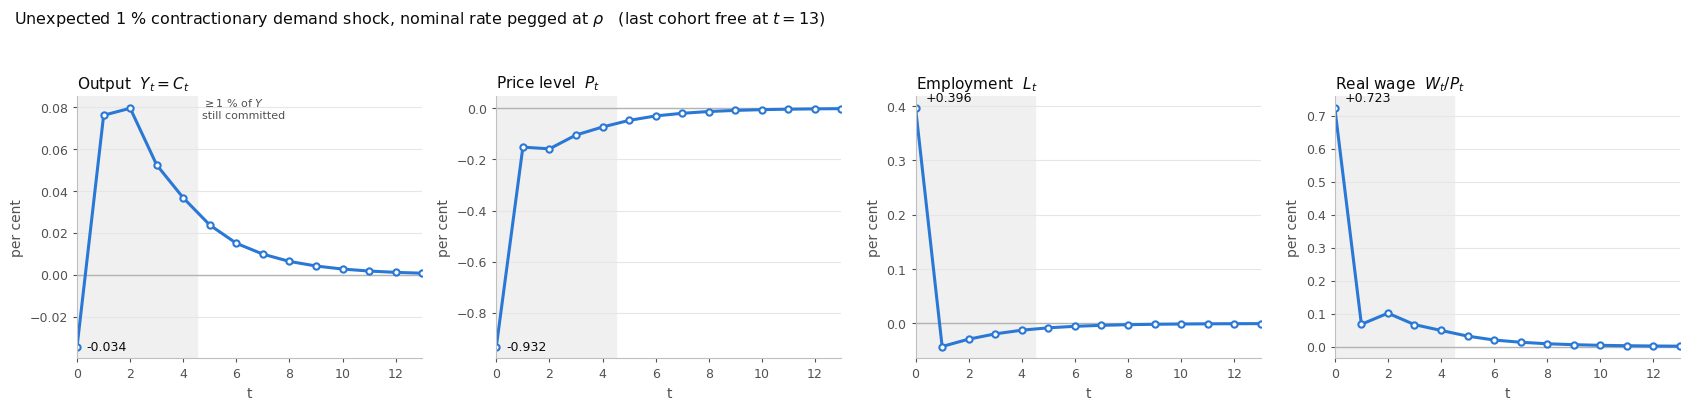

In [8]:
BLUE, ORANGE, INK, MUTED = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e'
H = 14

def style(ax):
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('0.75'); ax.spines['bottom'].set_color('0.75')
    ax.tick_params(colors=MUTED, labelsize=9, length=3)
    ax.grid(axis='y', color='0.9', lw=0.8); ax.set_axisbelow(True)
    ax.axhline(0, color='0.7', lw=1.0, zorder=1)
    ax.set_xlim(0, H - 1); ax.set_xlabel('t', color=MUTED)

t = np.arange(H)
panels = [('Output  $Y_t=C_t$', 100 * np.log(sol['Y'] / Y_ss)),
          ('Price level  $P_t$', 100 * np.log(sol['P'] / P_ss)),
          ('Employment  $L_t$',  100 * np.log(sol['L'] / L_ss)),
          ('Real wage  $W_t/P_t$', 100 * np.log((sol['W'] / sol['P']) / (W_ss / P_ss)))]

fig, axes = plt.subplots(1, 4, figsize=(17, 3.9))
fig.patch.set_facecolor('white')
for ax, (name, v) in zip(axes, panels):
    style(ax)
    ax.plot(t, v[:H], color=BLUE, lw=2.2, marker='o', ms=4.5, markerfacecolor='white',
            markeredgecolor=BLUE, markeredgewidth=1.5)
    ax.set_title(name, color=INK, fontsize=11, loc='left')
    ax.set_ylabel('per cent', color=MUTED)
    ax.annotate(f'{v[0]:+.3f}', xy=(0, v[0]), xytext=(7, -3 if v[0] < 0 else 5),
                textcoords='offset points', fontsize=9, color=INK)
committed = 100 * S_QTY * Y_ss ** ((1 - sigma) / sigma)
t_lock    = int(np.max(np.where(committed >= 1.0)[0]))     # last date with >= 1% still committed
for ax in axes:
    ax.axvspan(-0.5, t_lock + 0.5, color='0.94', zorder=0)
axes[0].text(t_lock + 0.7, axes[0].get_ylim()[1], f'$\\geq$1 % of $Y$\nstill committed',
             fontsize=8, color=MUTED, va='top', ha='left')
fig.suptitle(rf'Unexpected {100*D_SHOCK:.0f} % contractionary demand shock, nominal rate pegged at $\rho$'
             rf'   (last cohort free at $t={TAUMAX}$)',
             fontsize=11.5, color=INK, x=0.011, ha='left', y=1.04)
fig.tight_layout()
fig.savefig('../ss_demand_cohorts.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

## 7. The producers, cohort by cohort

Left: each cohort's *delivered output* is flat on zero until its own $\tau$, then jumps.  That
staircase is the whole mechanism — it is `generate_pattern_array_with_extra_rows` read one row
at a time.  On impact the single $\Delta=0$ producer absorbs everything, which is why its
response is an order of magnitude larger than anyone else's.

Right: the *labour input* of every cohort moves at $t=0$, because $l_{i,0}$ buys a delivery at
$\tau_i$, which is already a post-shock date.  Nothing about labour is committed.

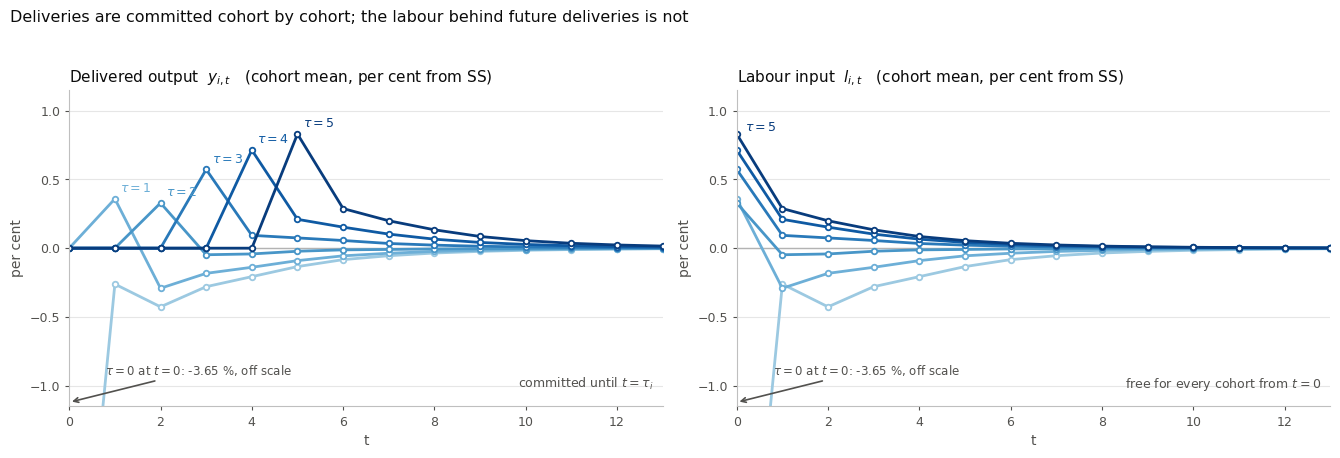

Output, per cent from steady state  (0.0000 = still committed)


,Y %,tau=0,tau=1,tau=2,tau=3,tau=4,tau=5
t,,,,,,,
0,-0.0341,-3.6499,0.0000,0.0000,0.0000,-0.0000,-0.0000
1,0.0760,-0.2612,0.3586,0.0000,0.0000,-0.0000,-0.0000
2,0.0794,-0.4264,-0.2912,0.3286,0.0000,-0.0000,-0.0000
3,0.0523,-0.2799,-0.1829,-0.0478,0.5720,-0.0000,-0.0000
4,0.0367,-0.2070,-0.1389,-0.0420,0.0932,0.7130,-0.0000
5,0.0237,-0.1338,-0.0905,-0.0223,0.0746,0.2097,0.8295
6,0.0150,-0.0833,-0.0557,-0.0123,0.0558,0.1528,0.2879
7,0.0099,-0.0548,-0.0369,-0.0092,0.0341,0.1023,0.1992
8,0.0064,-0.0352,-0.0236,-0.0056,0.0220,0.0654,0.1335


In [9]:
COHORTS = [k for k in range(6)]        # tau = 0..5 covers 261 of the 269 producers
ramp    = plt.cm.Blues(np.linspace(0.38, 0.95, len(COHORTS)))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
fig.patch.set_facecolor('white')

spec = [(axes[0], 'y', y_ss, 0,
         r'Delivered output  $y_{i,t}$',   'committed until $t=\\tau_i$'),
        (axes[1], 'l', l_ss, None,
         r'Labour input  $l_{i,t}$',       'free for every cohort from $t=0$')]
for ax, key, base, lab_at, name, note in spec:
    style(ax)
    for col, k in zip(ramp, COHORTS):
        m = tvals == k
        v = 100 * np.log(sol[key][:, m].mean(axis=1) / base[m].mean())
        ax.plot(t, v[:H], color=col, lw=2.0, marker='o', ms=4, markerfacecolor='white',
                markeredgecolor=col, markeredgewidth=1.3)
        if lab_at == 0:                       # deliveries: label each cohort where it unlocks
            ax.annotate(rf'$\tau={k}$', xy=(k, v[k]), xytext=(4, 5),
                        textcoords='offset points', fontsize=9, color=col)
        elif k in (0, COHORTS[-1]):           # labour: the extremes are enough, they all move
            ax.annotate(rf'$\tau={k}$', xy=(0, v[0]), xytext=(6, -2 if k == 0 else 2),
                        textcoords='offset points', fontsize=9, color=col)
    ax.set_title(name + '   (cohort mean, per cent from SS)', color=INK, fontsize=11, loc='left')
    ax.set_ylabel('per cent', color=MUTED)
    ax.text(0.985, 0.06, note, transform=ax.transAxes, ha='right', fontsize=9, color=MUTED)

# the tau = 0 cohort takes the entire impact on its own, far off the scale of the rest
for ax, key, base in [(axes[0], 'y', y_ss), (axes[1], 'l', l_ss)]:
    v0 = 100 * np.log(sol[key][0, tvals == 0].mean() / base[tvals == 0].mean())
    ax.set_ylim(-1.15, 1.15)
    ax.annotate(rf'$\tau=0$ at $t=0$: {v0:.2f} %, off scale',
                xy=(0, -1.12), xytext=(26, 20), textcoords='offset points', fontsize=8.5,
                color=MUTED, arrowprops=dict(arrowstyle='->', color=MUTED, lw=1.2))

fig.suptitle('Deliveries are committed cohort by cohort; the labour behind future deliveries '
             'is not', fontsize=11.5, color=INK, x=0.011, ha='left', y=1.03)
fig.tight_layout()
fig.savefig('../ss_demand_cohort_firms.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

coh = pd.DataFrame(
    {f'tau={k}': 100 * np.log(sol['y'][:, tvals == k].mean(axis=1) / y_ss[tvals == k].mean())
     for k in COHORTS},
    index=pd.Index(range(T), name='t')).iloc[:9]
coh.insert(0, 'Y %', 100 * np.log(sol['Y'] / Y_ss)[:9])
print('Output, per cent from steady state  (0.0000 = still committed)')
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(coh)

## 8. Where the shock goes

The date-0 wage and the date-0 price level are free; the date-0 *quantities* are not.  With
99 % of the aggregator committed, market clearing has to run through the price level, and the
deflation on impact creates the expected inflation that — under a peg — pulls the real rate
down and puts output slightly *above* steady state from $t=1$ while the cohorts unlock.

In [10]:
share_committed = 100 * S_QTY * Y_ss ** ((1 - sigma) / sigma)
dec = pd.DataFrame({
    'committed share of Y %': share_committed,
    'Y %':                    100 * np.log(sol['Y'] / Y_ss),
    'P %':                    100 * np.log(sol['P'] / P_ss),
    'expected inflation %':   100 * np.r_[sol['pi'][1:], 0.0],
    'real rate %':            100 * (rho - np.r_[sol['pi'][1:], 0.0]),
    'natural rate %':         100 * (rho - (np.r_[sol['xi'][1:], 0.0] - sol['xi'])),
}, index=pd.Index(range(T), name='t')).iloc[:8]
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(dec)

,committed share of Y %,Y %,P %,expected inflation %,real rate %,natural rate %
t,,,,,,
0,99.0514,-0.0341,-0.9317,0.7797,0.2203,0.0000
1,77.1840,0.0760,-0.1521,-0.0067,1.0067,1.0000
2,32.4865,0.0794,-0.1588,0.0541,0.9459,1.0000
3,12.1966,0.0523,-0.1047,0.0313,0.9687,1.0000
4,2.5708,0.0367,-0.0733,0.0259,0.9741,1.0000
5,0.2386,0.0237,-0.0474,0.0174,0.9826,1.0000
6,0.1598,0.0150,-0.0301,0.0103,0.9897,1.0000
7,0.0683,0.0099,-0.0197,0.0069,0.9931,1.0000


## 9. Contrast: what if the *price* were the committed variable?

Same staggering, but locked producers hold $p_i^{ss}$ and supply whatever is demanded — the
Calvo reading of the same cohorts.  The two conventions put the shock in opposite places.

price-committed: converged = True, max |residual| = 1.78e-15


,Y % quantity-committed,Y % price-committed,P % quantity-committed,P % price-committed
t,,,,
0,-0.0341,-0.4994,-0.9317,-0.0013
1,0.0760,0.0150,-0.1521,-0.0299
2,0.0794,0.0348,-0.1588,-0.0695
3,0.0523,0.0262,-0.1047,-0.0523
4,0.0367,0.0196,-0.0733,-0.0392
5,0.0237,0.0126,-0.0474,-0.0251
6,0.0150,0.0079,-0.0301,-0.0157
7,0.0099,0.0052,-0.0197,-0.0104


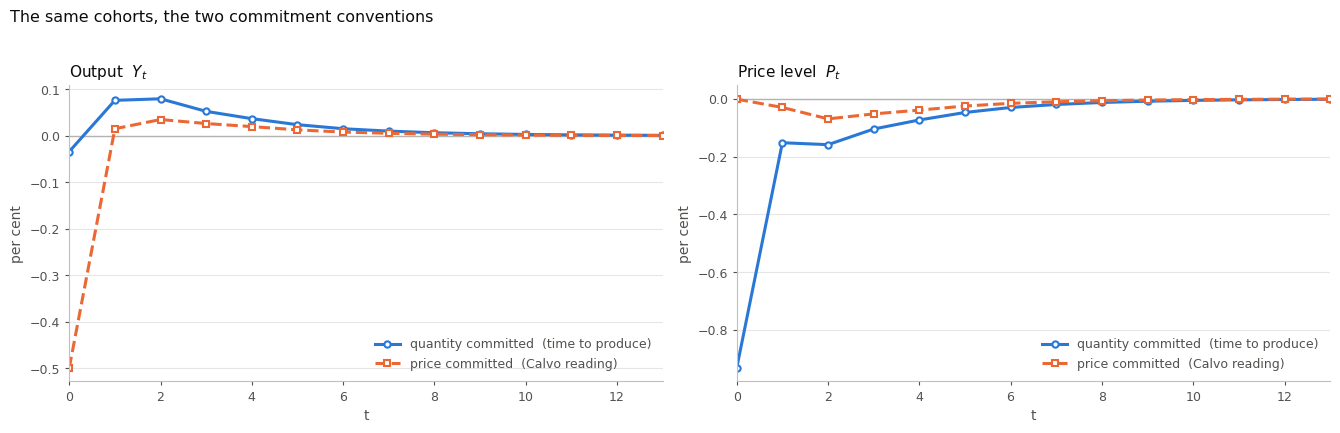

In [11]:
sol_p = solve(xi_base, mode='price')
print(f"price-committed: converged = {sol_p['success']}, max |residual| = {sol_p['maxres']:.2e}")

cmp = pd.DataFrame({
    'Y %  quantity-committed': 100 * np.log(sol['Y'] / Y_ss),
    'Y %  price-committed':    100 * np.log(sol_p['Y'] / Y_ss),
    'P %  quantity-committed': 100 * np.log(sol['P'] / P_ss),
    'P %  price-committed':    100 * np.log(sol_p['P'] / P_ss),
}, index=pd.Index(range(T), name='t')).iloc[:8]
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(cmp)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
fig.patch.set_facecolor('white')
for ax, key, base, name in [(axes[0], 'Y', Y_ss, 'Output  $Y_t$'),
                            (axes[1], 'P', P_ss, 'Price level  $P_t$')]:
    style(ax)
    ax.plot(t, 100 * np.log(sol[key] / base)[:H], color=BLUE, lw=2.2, marker='o', ms=4.5,
            markerfacecolor='white', markeredgecolor=BLUE, markeredgewidth=1.5,
            label='quantity committed  (time to produce)')
    ax.plot(t, 100 * np.log(sol_p[key] / base)[:H], color=ORANGE, lw=2.2, ls='--', marker='s',
            ms=4.5, markerfacecolor='white', markeredgecolor=ORANGE, markeredgewidth=1.5,
            label='price committed  (Calvo reading)')
    ax.set_title(name, color=INK, fontsize=11, loc='left')
    ax.set_ylabel('per cent', color=MUTED)
    ax.legend(frameon=False, fontsize=9, labelcolor=MUTED, loc='lower right')
fig.suptitle('The same cohorts, the two commitment conventions', fontsize=11.5, color=INK,
             x=0.011, ha='left', y=1.02)
fig.tight_layout()
fig.savefig('../ss_demand_cohorts_vs_prices.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

## 10. Shock sizes and persistence

The mechanism is close to linear in the size of the shock: because the impact response is
governed by how much of the aggregator is committed, not by the size of the impulse, the
impact split between output and prices is nearly invariant.

In [12]:
rows = []
for size in [0.005, 0.01, 0.03, 0.05]:
    for pers in [0.0, 0.6]:
        s = solve(demand_path(size, pers))
        rows.append({'shock %': 100 * size, 'persistence': pers,
                     'Y_0 %': 100 * np.log(s['Y'][0] / Y_ss),
                     'P_0 %': 100 * np.log(s['P'][0] / P_ss),
                     'L_0 %': 100 * np.log(s['L'][0] / L_ss),
                     'Y_0 % per 1% shock': 100 * np.log(s['Y'][0] / Y_ss) / (100 * size),
                     'P_0 % per 1% shock': 100 * np.log(s['P'][0] / P_ss) / (100 * size),
                     'peak |Y| %': 100 * np.max(np.abs(np.log(s['Y'] / Y_ss)))})
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(pd.DataFrame(rows))

,shock %,persistence,Y_0 %,P_0 %,L_0 %,Y_0 % per 1% shock,P_0 % per 1% shock,peak |Y| %
0,0.5000,0.0000,-0.0172,-0.4656,0.1978,-0.0344,-0.9313,0.0397
1,0.5000,0.6000,-0.0118,-0.4764,0.1357,-0.0236,-0.9528,0.0394
2,1.0000,0.0000,-0.0341,-0.9317,0.3957,-0.0341,-0.9317,0.0794
3,1.0000,0.6000,-0.0235,-0.9530,0.2714,-0.0235,-0.9530,0.0789
4,3.0000,0.0000,-0.0997,-2.8005,1.1876,-0.0332,-0.9335,0.2380
5,3.0000,0.6000,-0.0693,-2.8613,0.8152,-0.0231,-0.9538,0.2365
6,5.0000,0.0000,-0.1620,-4.6761,1.9802,-0.0324,-0.9352,0.3965
7,5.0000,0.6000,-0.1136,-4.7728,1.3603,-0.0227,-0.9546,0.3940


## Caveats

* $\Delta_i$ is held at its steady-state value throughout.  A producer re-optimising its
  *delay* as well as its scale is a separate margin — `semi_endo/semi_endo_A_price_reopt.ipynb`
  and `semi_endo_reopt_delta.png` are where that lives.
* "Unexpected" means only that dates before 0 were not conditioned on the shock, which is what
  locks the cohorts.  From $t=0$ on this is perfect foresight; the behavioural
  $\lambda$-discounting of `new_fixed_planner_myopic.ipynb` is not imposed here.
* Policy is a peg at $\rho$.  Under a peg the nominal level is pinned only by the terminal
  condition $P_T=P^{ss}$, which is the same selection the notebooks' backward Euler recursion
  makes.